# Импорт библиотек

In [1]:
# based on https://www.kaggle.com/konstanter/fasterrcnn-pytorch-maskdetection

import numpy as np 
import pandas as pd 
import torchvision
from torchvision import transforms, datasets, models
import torch
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as et
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
import cv2
import os
import glob

c:\Users\user\miniconda3\envs\cv\Lib\site-packages\albumentations\check_version.py:147: UserWarning: Error fetching version info <urlopen error _ssl.c:993: The handshake operation timed out>
  data = fetch_version_info()


In [2]:
torch.cuda.is_available()

True

### Скачивание датасета

Датасет **Face Mask Detection** (https://www.kaggle.com/datasets/andrewmvd/face-mask-detection). Если папки `./images` и `./annotations` уже на месте — скачивание пропускается. Без `kagglehub` датасет можно скачать вручную по ссылке выше и распаковать сюда же.


In [3]:
import os

if not (os.path.exists('images') and os.path.exists('annotations')):
    import kagglehub
    import shutil
    path = kagglehub.dataset_download('andrewmvd/face-mask-detection')
    for sub in ['images', 'annotations']:
        shutil.copytree(os.path.join(path, sub), sub,
                        dirs_exist_ok=True)
    print('Датасет скачан в:', path)
else:
    print('Датасет уже на месте: ./images, ./annotations')


Датасет уже на месте: ./images, ./annotations


# Загрузка данных в DataLoader

In [4]:
# путь к файлам
images_dir = './images/'
annotations_dir = './annotations/'


class FaceMaskDataset(torch.utils.data.Dataset):

    def __init__(self, images_dir, annotation_dir,width, height, transforms=None):
        self.transforms = transforms
        self.images_dir = images_dir
        self.annotation_dir = annotation_dir
        self.height = height
        self.width = width
        
        # сортировка изображений
        self.imgs = [image for image in sorted(os.listdir(images_dir))]
        self.annotate = [image for image in sorted(os.listdir(annotation_dir))]
        
        # на 0й позиции находится фон
        self.classes = ['_', 'without_mask','with_mask','mask_weared_incorrect']

    def __getitem__(self, idx):

        img_name = self.imgs[idx]
        image_path = os.path.join(self.images_dir, img_name)

        # изменение цвета и размера изображения    
        img = cv2.imread(image_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
        img_res = cv2.resize(img_rgb, (self.width, self.height), cv2.INTER_AREA)
        # нормализация изображения
        img_res /= 255.0
        
        # аннотация
        annot_filename = self.annotate[idx]
        annot_file_path = os.path.join(self.annotation_dir, annot_filename)
        
        boxes = []
        labels = []
        tree = et.parse(annot_file_path)
        root = tree.getroot()
        
        # высота и ширина изобрадения
        wt = img.shape[1]
        ht = img.shape[0]
        
        # ограничивающие рамки
        for member in root.findall('object'):
            labels.append(self.classes.index(member.find('name').text))
            
            # bounding box
            xmin = int(member.find('bndbox').find('xmin').text)
            xmax = int(member.find('bndbox').find('xmax').text)
            
            ymin = int(member.find('bndbox').find('ymin').text)
            ymax = int(member.find('bndbox').find('ymax').text)
            
            
            xmin_corr = (xmin/wt)*self.width
            xmax_corr = (xmax/wt)*self.width
            ymin_corr = (ymin/ht)*self.height
            ymax_corr = (ymax/ht)*self.height
            
            # обрезаем по границам: аннотации бывают чуть "за кадром"
            xmin_corr = max(0.0, min(xmin_corr, self.width - 1.0))
            ymin_corr = max(0.0, min(ymin_corr, self.height - 1.0))
            xmax_corr = max(1.0, min(xmax_corr, float(self.width)))
            ymax_corr = max(1.0, min(ymax_corr, float(self.height)))
            
            
            boxes.append([xmin_corr, ymin_corr, xmax_corr, ymax_corr])
        
        # перевод boxes в формат torch.Tensor
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])

        iscrowd = torch.zeros((boxes.shape[0],), dtype=torch.int64)
        
        labels = torch.as_tensor(labels, dtype=torch.int64)


        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["area"] = area
        target["iscrowd"] = iscrowd

        image_id = torch.tensor([idx])
        target["image_id"] = image_id


        if self.transforms:
            
            sample = self.transforms(image = img_res,
                                     bboxes = boxes.numpy(),
                                     labels = labels.numpy())
            
            img_res = sample['image']
            target['boxes'] = torch.as_tensor(sample['bboxes'], dtype=torch.float32)
            target['labels'] = torch.as_tensor(sample['labels'], dtype=torch.int64)
            
            
        return img_res, target

    def __len__(self):
        return len(self.imgs)


# проверка датасета
dataset = FaceMaskDataset(images_dir, annotations_dir, 512, 512)
print('length of dataset = ', len(dataset), '\n')

img, target = dataset[78]
print('Image shape = ', img.shape, '\n','Target - ', target)

length of dataset =  853 

Image shape =  (512, 512, 3) 
 Target -  {'boxes': tensor([[258.5515, 335.3600, 374.2193, 469.7600]]), 'labels': tensor([2]), 'area': tensor([15545.7529]), 'iscrowd': tensor([0]), 'image_id': tensor([78])}


In [5]:
# Индексы изображений, содержащих редкий класс mask_weared_incorrect
# (всего 123 объекта из 4072, ~3% — класс занижает macro-mAP;
# ниже дублируем эти изображения в train обеих моделей)
import xml.etree.ElementTree as et

rare_idx = set()
for i, name in enumerate(sorted(os.listdir(images_dir))):
    base = os.path.splitext(name)[0]
    root = et.parse(os.path.join(annotations_dir, base + '.xml')).getroot()
    if any(o.find('name').text == 'mask_weared_incorrect'
           for o in root.findall('object')):
        rare_idx.add(i)
print(f'Изображений с mask_weared_incorrect: {len(rare_idx)} '
      f'из {len(os.listdir(images_dir))}')


Изображений с mask_weared_incorrect: 97 из 853


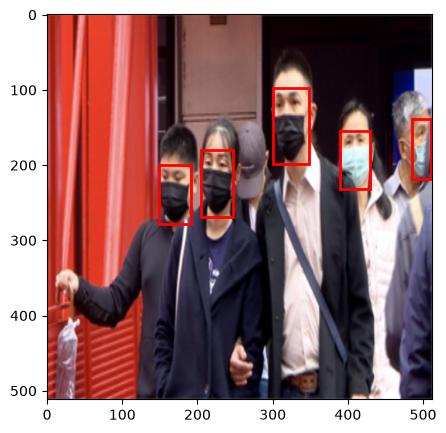

In [6]:
# Вспомогательная функция для визуализации bbox

def plot_img_bbox(img, target):
    fig, a = plt.subplots(1,1)
    fig.set_size_inches(5,5)
    a.imshow(img)
    for box in (target['boxes']):
        x, y, width, height  = box[0], box[1], box[2]-box[0], box[3]-box[1]
        rect = patches.Rectangle((x, y),
                                 width, height,
                                 linewidth = 2,
                                 edgecolor = 'r',
                                 facecolor = 'none')

        # Отрисуем bbox поверх картинки
        a.add_patch(rect)
    plt.show()
rm = np.random.randint(0,100)    
img, target = dataset[rm]
plot_img_bbox(img, target)

In [7]:
def collate_fn(batch):
    return tuple(zip(*batch))

In [8]:
# dataset_test создаётся с применением трансформации для тестового набора
def get_transform(train):
    if train:
        return A.Compose(
            [
                A.HorizontalFlip(0.5),
                A.RandomBrightnessContrast(p=0.2),
                A.ShiftScaleRotate(shift_limit=0.2, scale_limit=0.2, rotate_limit=30, p=0.5),
                ToTensorV2(p=1.0),
            ],
            bbox_params=A.BboxParams(
                format="pascal_voc",
                label_fields=["labels"],
                clip=True,
                min_area=1,
            ),
        )
    else:
        return A.Compose(
            [
                ToTensorV2(p=1.0),
            ],
            bbox_params=A.BboxParams(
                format="pascal_voc",
                label_fields=["labels"],
                clip=True,
                min_area=1,
            ),
        )
        
dataset_full = FaceMaskDataset(
    images_dir, annotations_dir, 512, 512, transforms=get_transform(train=True))

dataset_test = FaceMaskDataset(
    images_dir, annotations_dir, 512, 512, transforms=get_transform(train=False)
)

# разделим данные на train и test
torch.manual_seed(1)
indices = torch.randperm(len(dataset_full)).tolist()

test_split = 0.2
tsize = int(len(dataset_full)*test_split)
# oversampling редкого класса: дублируем его train-индексы (x3)
train_indices = indices[:-tsize] + [i for i in indices[:-tsize]
                                    if i in rare_idx] * 3
dataset = torch.utils.data.Subset(dataset_full, train_indices)
dataset_test = torch.utils.data.Subset(dataset_test, indices[-tsize:])

data_loader = torch.utils.data.DataLoader(
    dataset, batch_size=10, shuffle=True, num_workers=0,
    collate_fn=collate_fn)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=10, shuffle=False, num_workers=0,
    collate_fn=collate_fn)



c:\Users\user\miniconda3\envs\cv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
c:\Users\user\miniconda3\envs\cv\Lib\site-packages\albumentations\core\composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


### Отрисовка одного батча загруженных данных


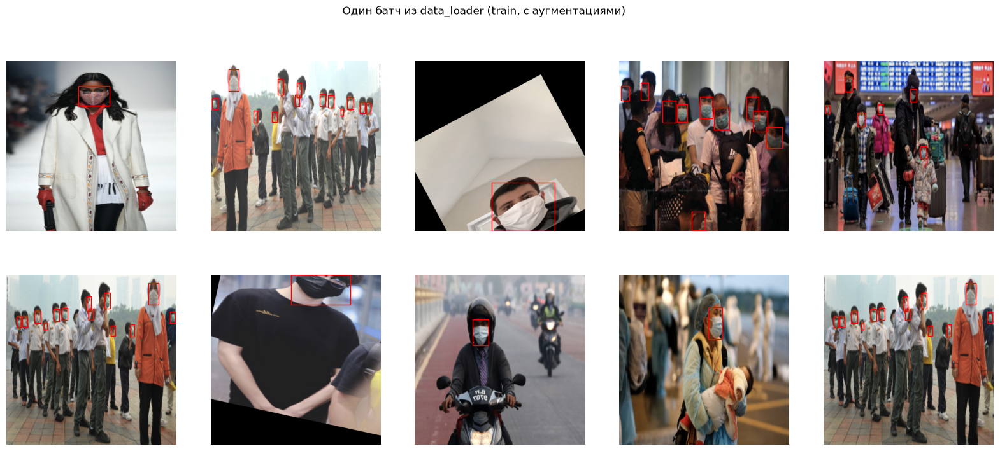

In [9]:
# Берём свежий батч из train-загрузчика (после аугментаций)
imgs_batch, anns_batch = next(iter(data_loader))

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, img, ann in zip(axes.flat, imgs_batch, anns_batch):
    ax.imshow(img.detach().cpu().permute(1, 2, 0))
    for box in ann['boxes'].detach().cpu().numpy():
        x, y = box[0], box[1]
        ax.add_patch(patches.Rectangle(
            (x, y), box[2] - box[0], box[3] - box[1],
            linewidth=1, edgecolor='r', facecolor='none'))
    ax.axis('off')
plt.suptitle('Один батч из data_loader (train, с аугментациями)')
plt.show()


## Выбор модели

**Faster R-CNN (backbone ResNet-50 + FPN)** — двухстадийный детектор, эталон качества в detection-задачах. Предобучен на COCO (80 категорий, включая «person»): лица на наших фото близки к данным COCO, поэтому transfer learning сработает хорошо. FPN позволяет детектировать объекты разного масштаба (лица вдали и вблизи). Заменяем только «голову» (`FastRCNNPredictor`) под 3 класса + фон (4 выхода), остальная сеть дообучается. Baseline для сравнения с YOLOv8s.

**YOLOv8s** — одностадийный детектор, разумный компромисс скорость/качество. Выбран как вторая модель для сравнения парадигм: two-stage (Faster R-CNN) vs one-stage (YOLO). В процессе получения лучшей метрики mAP@0.5>=0.85 заменим на YOLOv8m (medium) для повышения качества. Предобучен на COCO, поэтому transfer learning сработает хорошо. В отличие от Faster R-CNN, YOLOv8 не требует ручной замены «головы» под 3 класса + фон: сеть сама подстроится под количество классов в `data.yaml`.


# Обучение модели

In [10]:
# Faster R-CNN с backbone ResNet-50 + FPN.
# weights="DEFAULT" = предобученные на COCO веса (transfer learning;
# устаревший аргумент pretrained=True не используем).
# Заменяем только голову-классификатор под наши классы (3 класса + фон).
def get_detection_model(num_classes):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features,
                                                      num_classes)
    return model


In [11]:
from tqdm import tqdm

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

num_classes = 4

print('device = ', device, '\n')

model = get_detection_model(num_classes)

num_epochs = 16  # было 8: модель недообучалась

model.to(device)


params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005,
                                momentum=0.9, weight_decay=0.0005)

lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=3,
                                               gamma=0.1)
len_dataloader = len(data_loader)

for epoch in tqdm(range(num_epochs)):
    model.train()
    i = 0    
    epoch_loss = 0
    for imgs, annotations in data_loader:
        i += 1
        imgs = [img.float().to(device) for img in imgs]
        annotations = [{k: v.to(device) for k, v in t.items()} for t in annotations]
        loss_dict = model(imgs, annotations)
        losses = sum(loss for loss in loss_dict.values())        

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()         
        epoch_loss += losses.item()
    lr_scheduler.step()  # <-- scheduler 
    print(f'Epoch {epoch}: mean_loss = {epoch_loss / len(data_loader):.4f}')

# сохраняем веса, чтобы не переобучать при повторном запуске оценки
torch.save(model.state_dict(), 'frcnn_mask.pt')
print('Веса сохранены в frcnn_mask.pt')


device =  cuda 



  6%|▋         | 1/16 [01:35<23:59, 95.99s/it]

Epoch 0: mean_loss = 0.6128


 12%|█▎        | 2/16 [02:52<19:40, 84.31s/it]

Epoch 1: mean_loss = 0.4184


 19%|█▉        | 3/16 [04:07<17:24, 80.38s/it]

... (24 outputs left out)

Epoch 14: mean_loss = 0.3112


100%|██████████| 16/16 [20:56<00:00, 78.50s/it]

Epoch 15: mean_loss = 0.3106


Веса сохранены в frcnn_mask.pt


In [12]:
# вспомогательная функция принимает исходный прогноз и порог iou

def apply_nms(orig_prediction, iou_thresh=0.3):
    
    keep = torchvision.ops.nms(orig_prediction['boxes'], orig_prediction['scores'], iou_thresh)
    
    final_prediction = orig_prediction
    final_prediction['boxes'] = final_prediction['boxes'][keep]
    final_prediction['scores'] = final_prediction['scores'][keep]
    final_prediction['labels'] = final_prediction['labels'][keep]
    
    return final_prediction

def torch_to_pil(img):
    return transforms.ToPILImage()(img).convert('RGB')

In [13]:
img, target = dataset_test[4]

model.eval()
with torch.no_grad():
    prediction = model([img.to(device)])[0]

# переносим предсказание на CPU: дальше с ним работает matplotlib и NMS
prediction = {k: v.cpu() for k, v in prediction.items()}
    
print('predicted #boxes: ', len(prediction['labels']))
print('real #boxes: ', len(target['labels']))

predicted #boxes:  3
real #boxes:  1


In [14]:
from torchmetrics.detection import MeanAveragePrecision

metric = MeanAveragePrecision(iou_type="bbox", class_metrics=True)
model.eval()
with torch.no_grad():
    for imgs_v, anns_v in data_loader_test:
        imgs_v = [img.to(device) for img in imgs_v]
        preds_v = model(imgs_v)
        # torchmetrics ждёт оба на одном устройстве; переводим target на GPU
        anns_v = [{k: v.to(device) for k, v in t.items()} for t in anns_v]
        metric.update(preds_v, anns_v)

res = metric.compute()
print(f"mAP@0.5:0.95 = {res['map']:.4f}")
print(f"mAP@0.5      = {res['map_50']:.4f}")
print(f"AP per class = {res['map_per_class']}")  # классы: without_mask, with_mask, mask_weared_incorrect

mAP@0.5:0.95 = 0.3955
mAP@0.5      = 0.7046
AP per class = tensor([0.3623, 0.5372, 0.2871])


EXPECTED OUTPUT


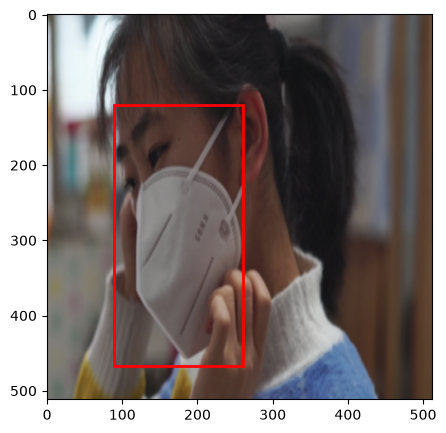

In [15]:
print('EXPECTED OUTPUT')
plot_img_bbox(torch_to_pil(img), target)

MODEL OUTPUT


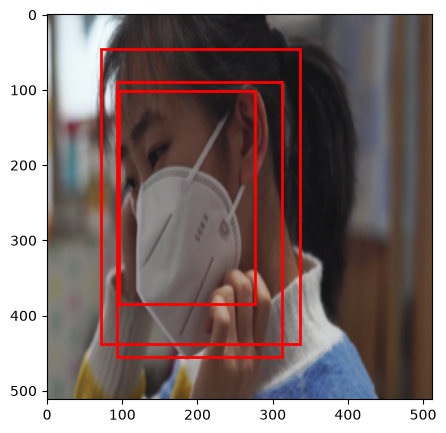

In [16]:
print('MODEL OUTPUT')
plot_img_bbox(torch_to_pil(img), prediction)

NMS APPLIED MODEL OUTPUT


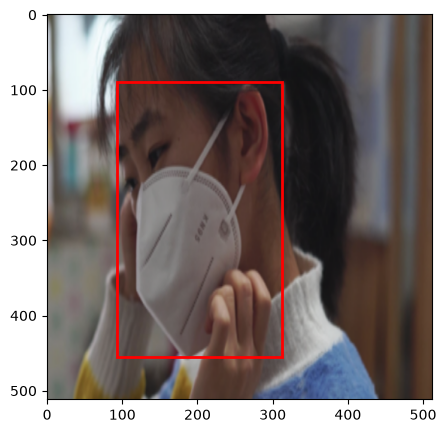

In [17]:
nms_prediction = apply_nms(prediction, iou_thresh=0.2)
print('NMS APPLIED MODEL OUTPUT')
plot_img_bbox(torch_to_pil(img), nms_prediction)

# Отрисовка изображений

In [18]:
def plot_image(img_tensor, annotation, predict=True):
    
    fig,ax = plt.subplots(1)
    fig.set_size_inches(18.5, 10.5)
    img = img_tensor.detach().cpu()
    mask_dic = {1:'without_mask', 2:'with_mask', 3:'mask_weared_incorrect'}

    ax.imshow(img.permute(1, 2, 0))
    
     # единообразно забираем всё на CPU и в numpy/числа
    boxes = annotation['boxes'].detach().cpu().numpy()
    labels = annotation['labels'].detach().cpu().numpy()
    scores = annotation['scores'].detach().cpu().numpy() if predict else None
    
    for i,box in enumerate(boxes):
        xmin, ymin, xmax, ymax = box

        rect = patches.Rectangle((xmin,ymin),(xmax-xmin),(ymax-ymin),linewidth=1,edgecolor='r',facecolor='none')

        ax.add_patch(rect)
        label = mask_dic[int(labels[i])]
        if predict:
            score=int(scores[i] * 100)
            ax.text(xmin, ymin, f"{label} : {score}%", horizontalalignment='center', verticalalignment='center',fontsize=20,color='b')
        else:
            
            ax.text(xmin, ymin, f"{label}", horizontalalignment='center', verticalalignment='center',fontsize=20,color='b')
    plt.show()

In [19]:
# Берём один ТЕСТОВЫЙ батч для визуализации предсказаний
for imgs, annotations in data_loader_test:
    imgs = list(img.to(device) for img in imgs)
    annotations = [{k: v.to(device) for k, v in t.items()} for t in annotations]
    break


In [20]:
model.eval()
preds = model(imgs)

Prediction


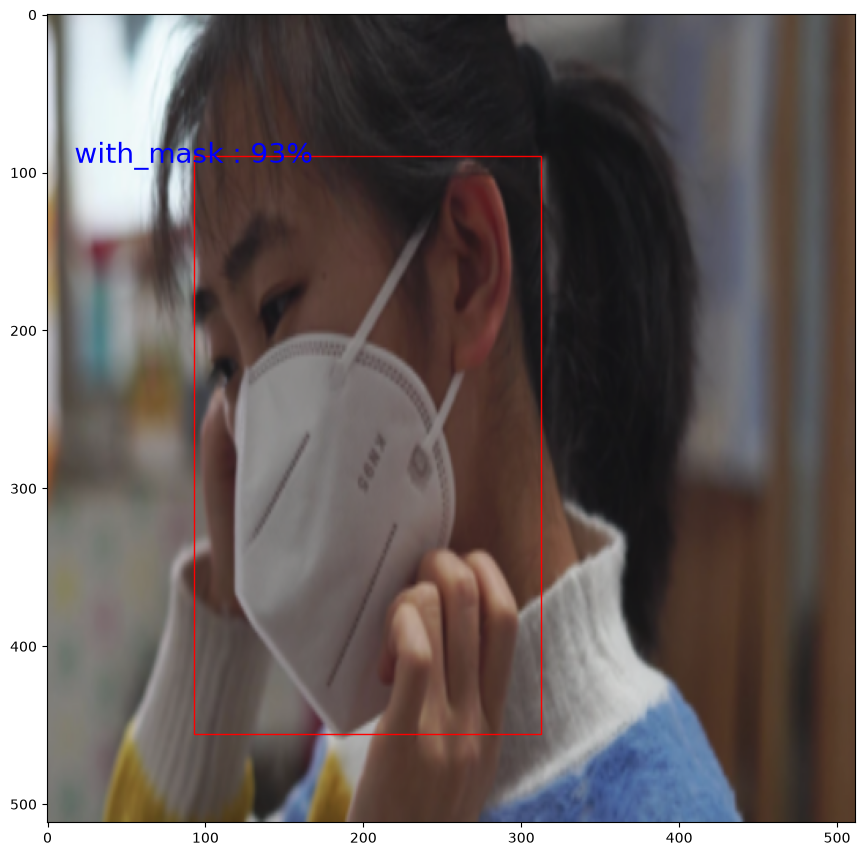

Target


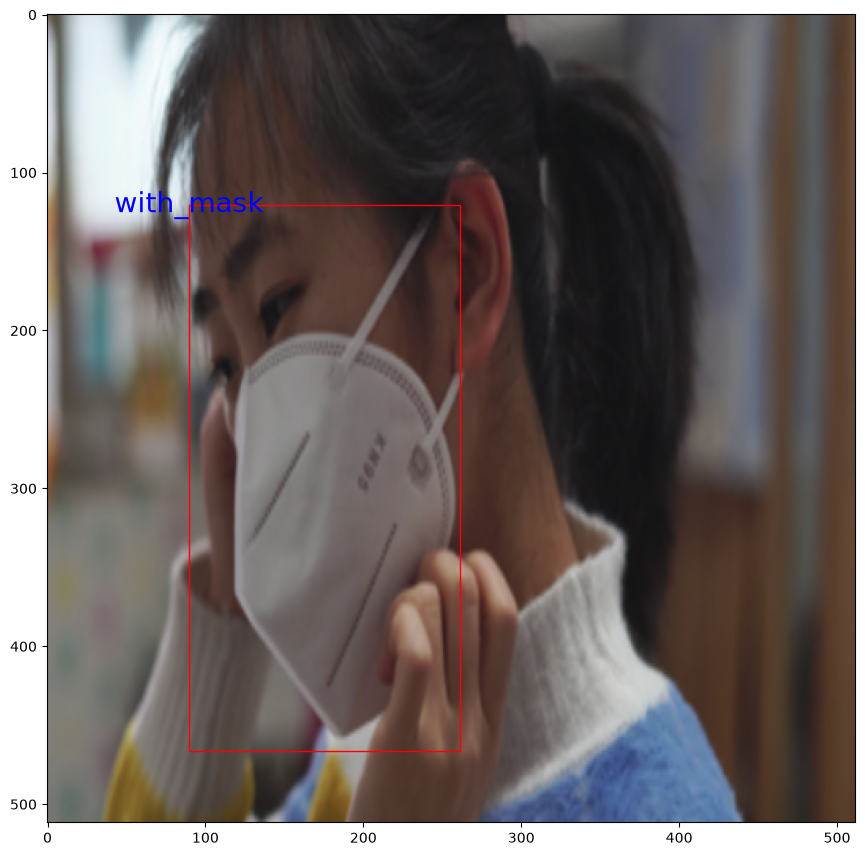

In [21]:
nms_prediction = apply_nms(preds[4], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[4], nms_prediction)
print("Target")
plot_image(imgs[4].to('cpu'), annotations[4],False)

Prediction


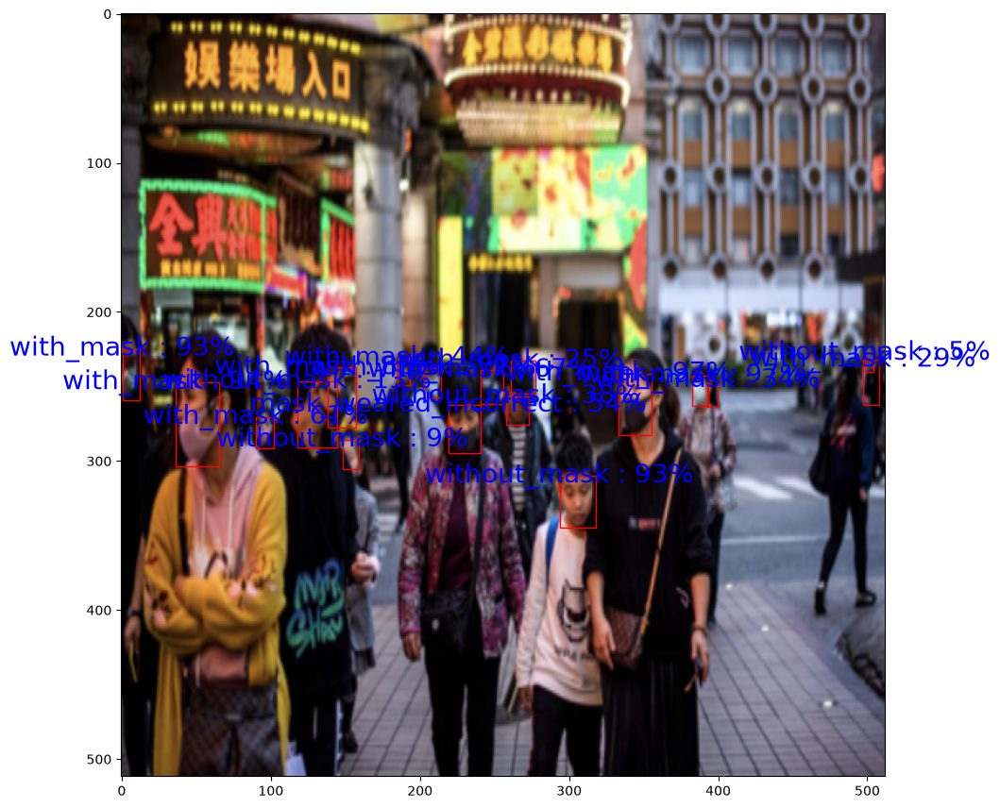

Target


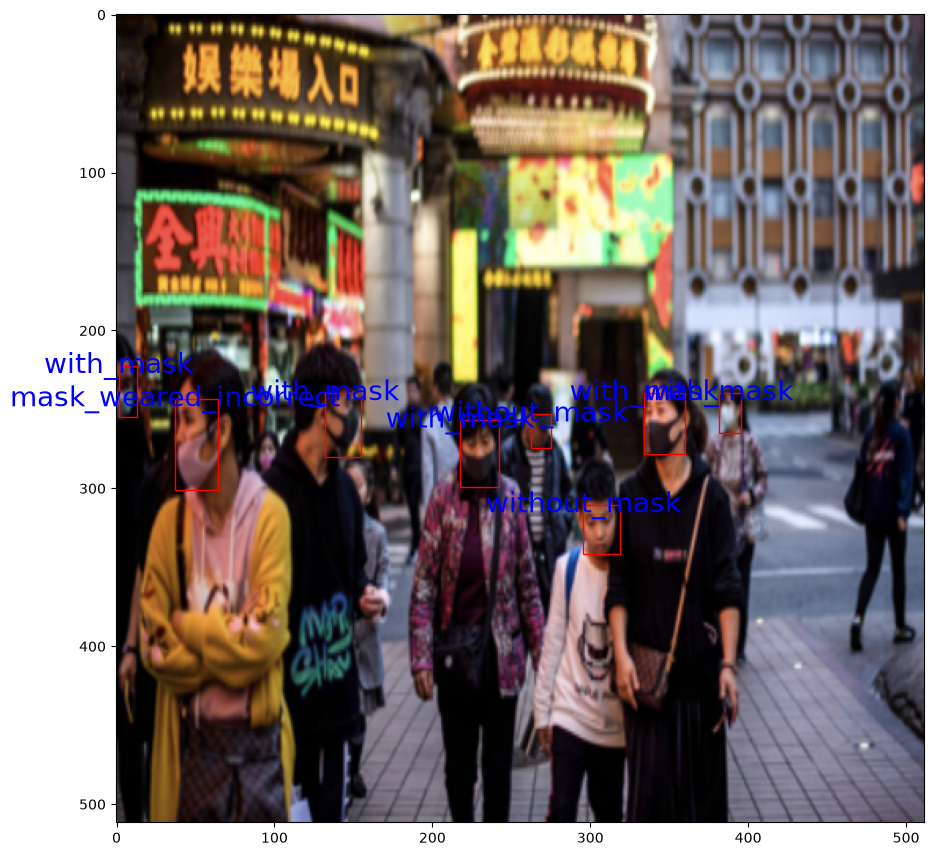

In [22]:
nms_prediction = apply_nms(preds[7], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[7], nms_prediction)
print("Target")
plot_image(imgs[7].to('cpu'), annotations[7],False)

Prediction


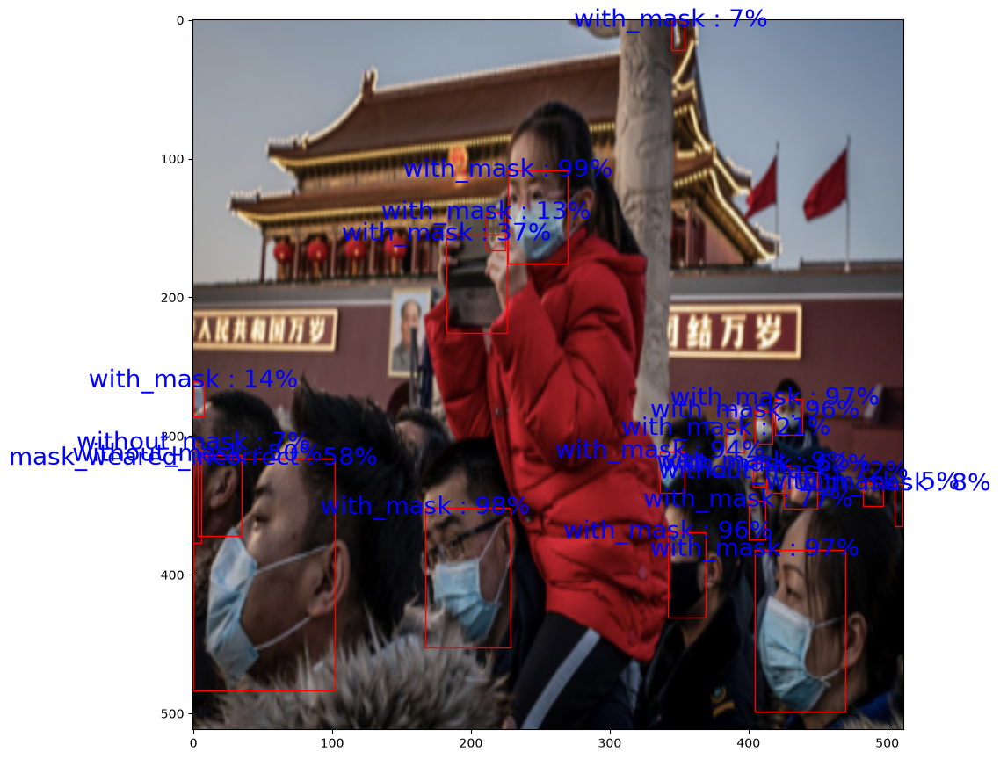

Target


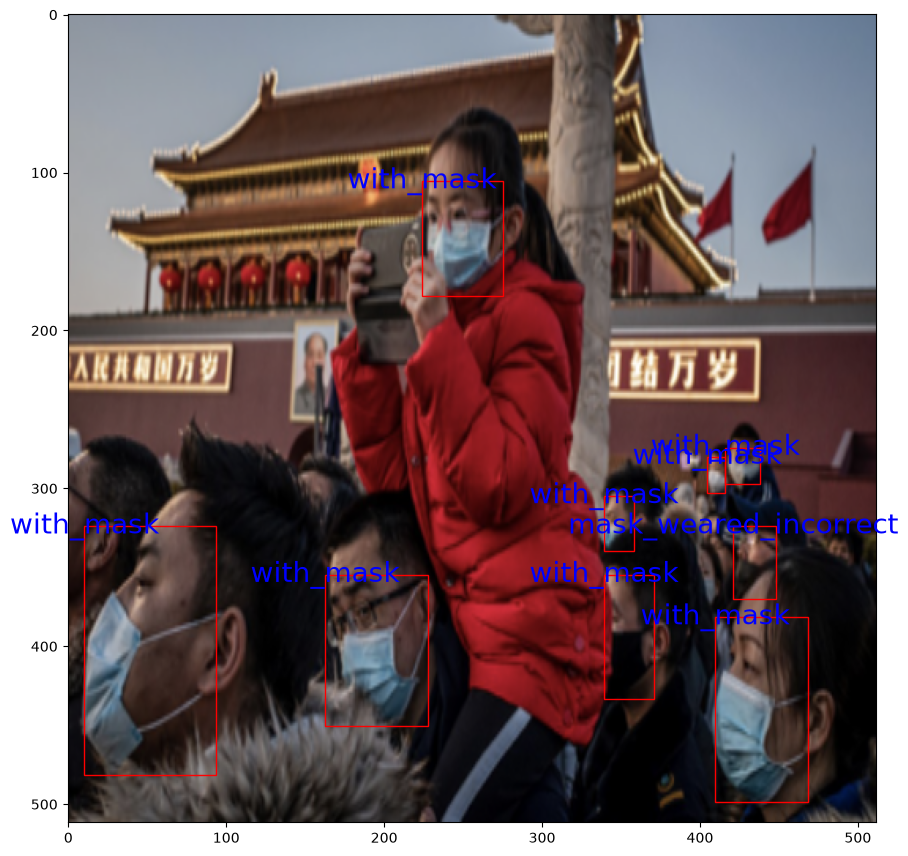

In [23]:
nms_prediction = apply_nms(preds[0], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[0], nms_prediction)
print("Target")
plot_image(imgs[0].to('cpu'), annotations[0],False)

Prediction


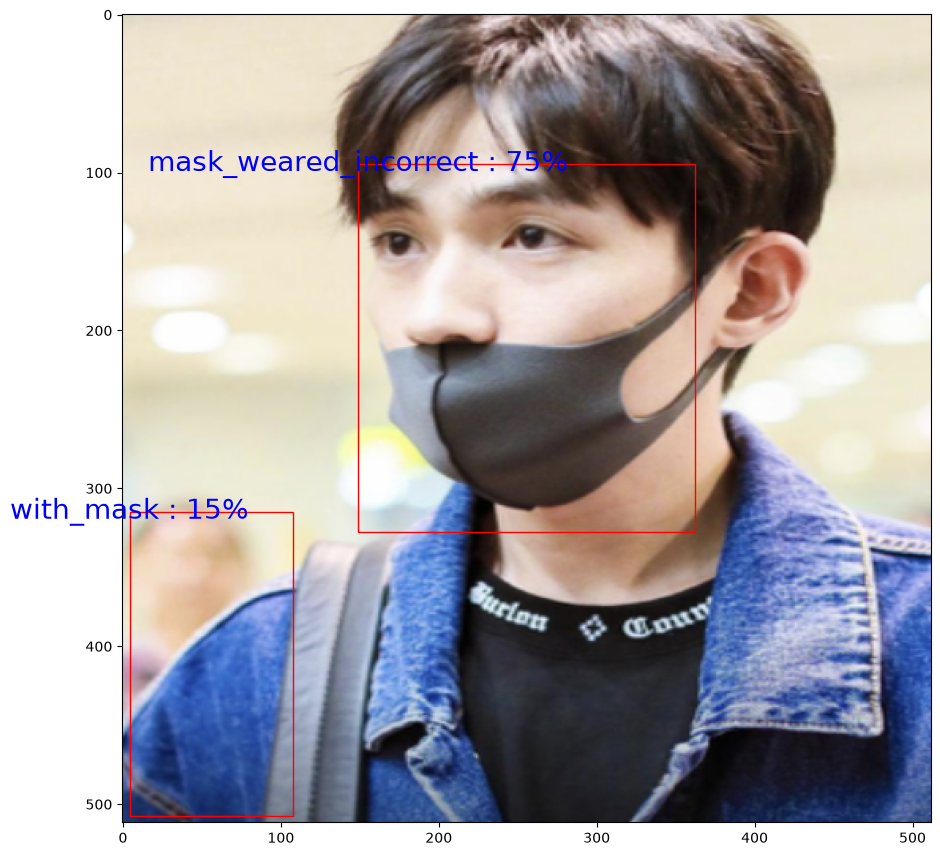

Target


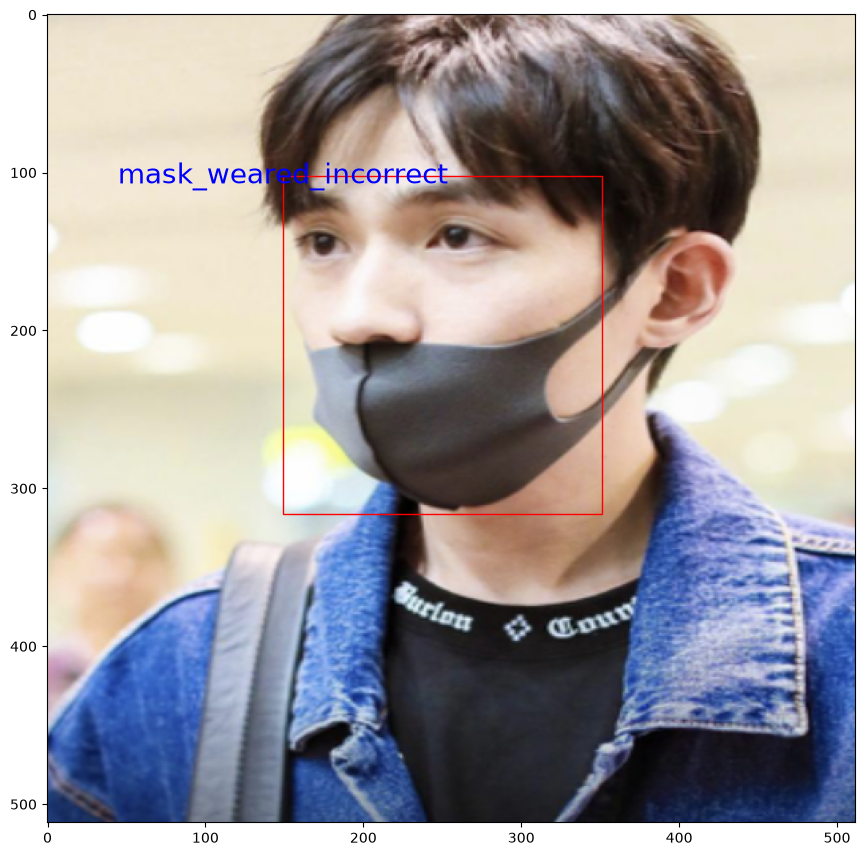

In [24]:
nms_prediction = apply_nms(preds[2], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[2], nms_prediction)
print("Target")
plot_image(imgs[2].to('cpu'), annotations[2],False)

Faster R-CNN mean IoU (сматченные пары, IoU>=0.5): 0.7890


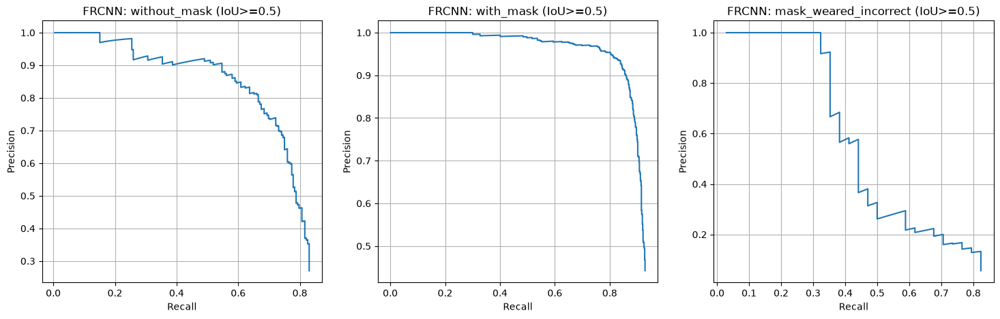

In [25]:
from torchvision.ops import box_iou

# Faster R-CNN: mean IoU и PR-кривые (порог IoU = 0.5)
# Сопоставление prediction<->GT жадное, one-to-one: каждый GT-бокс
# может быть засчитан не более одного раза (иначе TP завышаются).
names = {1: 'without_mask', 2: 'with_mask', 3: 'mask_weared_incorrect'}
curves = {c: {'scores': [], 'hits': [], 'n_gt': 0} for c in names}
ious_matched = []  # IoU сматченных пар — для mean IoU

model.eval()
with torch.no_grad():
    for imgs_v, anns_v in data_loader_test:
        preds_v = model([img.to(device) for img in imgs_v])
        for p, t in zip(preds_v, anns_v):
            p = {k: v.cpu() for k, v in p.items()}
            # сортируем предсказания по убыванию score (порядок для greedy)
            order = torch.argsort(p['scores'], descending=True)
            p_boxes = p['boxes'][order]
            p_labels = p['labels'][order]
            p_scores = p['scores'][order]
            iou = box_iou(p_boxes, t['boxes']) if len(p_boxes) and len(t['boxes']) else None
            matched_gt = set()
            for i in range(len(p_boxes)):
                li = int(p_labels[i])
                hit = False
                if iou is not None:
                    cand = [j for j in (t['labels'] == li).nonzero().flatten().tolist()
                            if j not in matched_gt]
                    if cand:
                        j_best = max(cand, key=lambda j: iou[i, j])
                        if iou[i, j_best] >= 0.5:
                            hit = True
                            matched_gt.add(j_best)
                            ious_matched.append(float(iou[i, j_best]))
                if li in curves:
                    curves[li]['scores'].append(float(p_scores[i]))
                    curves[li]['hits'].append(hit)
            for c in names:
                curves[c]['n_gt'] += int((t['labels'] == c).sum())

if ious_matched:
    print(f'Faster R-CNN mean IoU (сматченные пары, IoU>=0.5): {np.mean(ious_matched):.4f}')
else:
    print('Faster R-CNN: нет сматченных пар — проверьте обучение')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (c, d) in zip(axes, curves.items()):
    if len(d['scores']) == 0:
        ax.set_title(f"FRCNN: {names[c]} — нет предсказаний")
        continue
    order = np.argsort(d['scores'])[::-1]
    hits = np.array(d['hits'])[order]
    tp = np.cumsum(hits)
    fp = np.cumsum(~hits)
    prec = tp / np.maximum(tp + fp, 1)
    rec = tp / max(d['n_gt'], 1)
    ax.plot(rec, prec)
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_title(f'FRCNN: {names[c]} (IoU>=0.5)')
    ax.grid(True)
plt.show()


## Модель YOLOv8

In [26]:
import os, shutil
import xml.etree.ElementTree as et

src_img, src_ann = './images/', './annotations/'
classes = ['without_mask', 'with_mask', 'mask_weared_incorrect']  # id: 0,1,2

def convert(split, img_names, out_root='./yolo_data'):
    for sub in ['images', 'labels']:
        os.makedirs(f'{out_root}/{sub}/{split}', exist_ok=True)
    for name in img_names:
        base = os.path.splitext(name)[0]
        shutil.copy(os.path.join(src_img, name), f'{out_root}/images/{split}/{name}')
        root = et.parse(os.path.join(src_ann, base + '.xml')).getroot()
        w = float(root.find('size/width').text)
        h = float(root.find('size/height').text)
        lines = []
        for obj in root.findall('object'):
            cid = classes.index(obj.find('name').text)
            bb = obj.find('bndbox')
            xmin, ymin = float(bb.find('xmin').text), float(bb.find('ymin').text)
            xmax, ymax = float(bb.find('xmax').text), float(bb.find('ymax').text)
            xc, yc = (xmin + xmax) / 2 / w, (ymin + ymax) / 2 / h
            bw, bh = (xmax - xmin) / w, (ymax - ymin) / h
            # клиппинг в [0, 1]: аннотации бывают чуть "за кадром"
            xc = min(max(xc, 0.0), 1.0); yc = min(max(yc, 0.0), 1.0)
            bw = min(max(bw, 0.0), 1.0); bh = min(max(bh, 0.0), 1.0)
            lines.append(f'{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}')
        with open(f'{out_root}/labels/{split}/{base}.txt', 'w') as f:
            f.write('\n'.join(lines))

# тот же сплит, что и в Faster R-CNN (seed=1, 80/20) — честное сравнение
import torch
torch.manual_seed(1)
all_imgs = sorted(os.listdir(src_img))
indices = torch.randperm(len(all_imgs)).tolist()
tsize = int(len(all_imgs) * 0.2)
convert('train', [all_imgs[i] for i in indices[:-tsize]])
convert('val',   [all_imgs[i] for i in indices[-tsize:]])
# oversampling редкого класса: дубли с суффиксом _dup{k}
# (те же train-индексы, что и у FRCNN — сравнение остаётся честным)
n_extra = 0
for i in indices[:-tsize]:
    if i not in rare_idx:
        continue
    base = os.path.splitext(all_imgs[i])[0]
    for k in range(3):
        new_base = f'{base}_dup{k}'
        shutil.copy(os.path.join(src_img, all_imgs[i]),
                    f'./yolo_data/images/train/{new_base}.png')
        shutil.copy(f'./yolo_data/labels/train/{base}.txt',
                    f'./yolo_data/labels/train/{new_base}.txt')
        n_extra += 1
print('oversampling: добавлено дублей в train:', n_extra)
print('done')

oversampling: добавлено дублей в train: 210
done


In [27]:
# Создаём конфиг датасета для YOLO программно 
import yaml

data_config = {
    'path': './yolo_data',      # корень конвертированного датасета
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'without_mask',
        1: 'with_mask',
        2: 'mask_weared_incorrect'
    }
}

with open('data.yaml', 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False, allow_unicode=True)

print(open('data.yaml').read())

names:
  0: without_mask
  1: with_mask
  2: mask_weared_incorrect
path: ./yolo_data
train: images/train
val: images/val



In [28]:
from ultralytics import YOLO

model_yolo = YOLO("yolov8m.pt")  # pretrained backbone+neck с COCO: transfer learning

model_yolo.train(
    data="data.yaml",
    epochs=100,     # было 50: прогон оборвался на 34 эпохе, mAP50 ещё рос
    imgsz=768,        # было 640: на 768 точность выше, но GPU требует больше памяти
    batch=6,          # -было 8: ищем оптимальное значение под GPU
    patience=20,      # early stopping (было 10 — срабатывал слишком рано)
    lr0=5e-4,         # было 1e-3
    cos_lr=True,    # было False: плавное снижение lr к концу обучения
    optimizer='AdamW', # было SGD: Adam
    weight_decay=0.0005, # было по умолчанию
    workers=0,        # Windows + Jupyter: иначе зависания
    pretrained=True,
    # --- аугментации ---
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,   # цвет/яркость: маски при разном освещении
    degrees=10.0,                        # небольшие повороты головы
    translate=0.1, scale=0.5,            # сдвиги и масштаб
    fliplr=0.5,                          # зеркало — лица симметричны, бесплатный x2 данных
    mosaic=1.0,
    close_mosaic=10,                     # последние 10 эпох без mosaic — "доводка" на чистых данных
    copy_paste=0.1                       # перенос масок между фото — отлично для редкого класса
)

# берём ЛУЧШИЕ веса (early stopping мог остановить обучение раньше)
best_pt = str(model_yolo.trainer.best)
print('best weights:', best_pt)
model_yolo = YOLO(best_pt)



New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.12.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0

In [29]:
metrics = model_yolo.val(data="data.yaml", imgsz=768, plots=True)
print("mAP@0.5      =", metrics.box.map50)
print("mAP@0.5:0.95 =", metrics.box.map)
print("Графики (PR-кривая и др.) сохранены в:", metrics.save_dir)


Ultralytics 8.4.190  Python-3.12.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
Model summary (fused): 92 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2155.7±566.4 MB/s, size: 543.6 KB)
val: Scanning D:\Skillfactory_local\ML\CV\Project2_CV\yolo_data\labels\val.cache... 170 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 170/170  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2s/it 23.8s0.3s
                   all        170       1074      0.899       0.79      0.865      0.542
          without_mask         65        212       0.91      0.764      0.904      0.531
             with_mask        152        828      0.932      0.907      0.947      0.617
 mask_weared_incorrect         27         34      0.856      0.698      0.744      0.476
Speed: 1.6ms preprocess, 11.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Results 

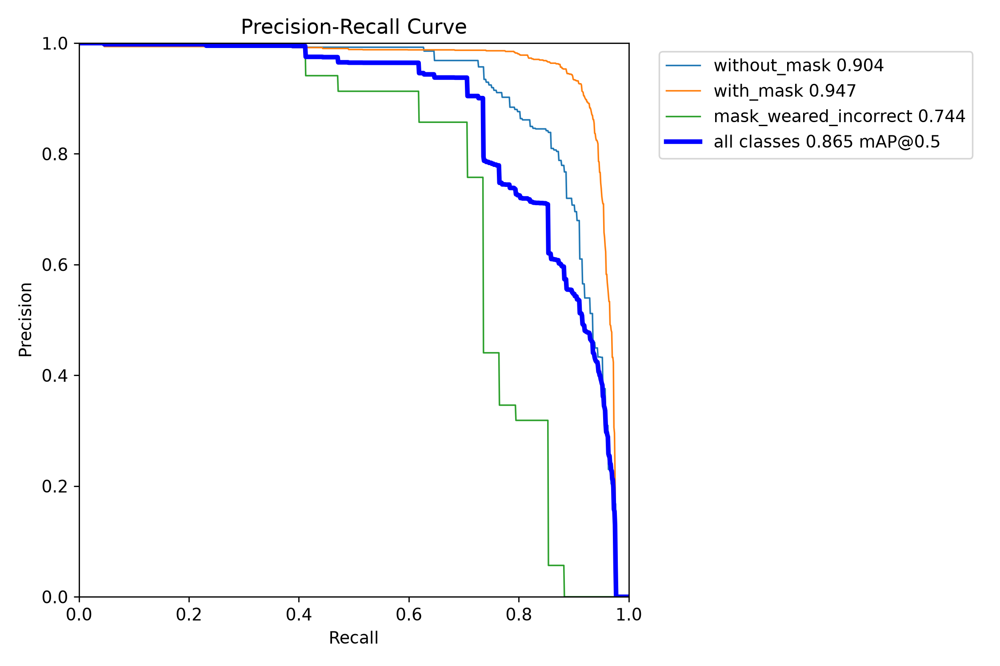

In [30]:
# PR-кривая YOLOv8 из ПОСЛЕДНЕГО запуска val() (путь из metrics.save_dir)
Image.open(os.path.join(str(metrics.save_dir), "BoxPR_curve.png"))



In [31]:
print(f"Требуемый результат получен: mAP50 > 0.85: {metrics.box.map50:.4f}")

Требуемый результат получен: mAP50 > 0.85: 0.8649


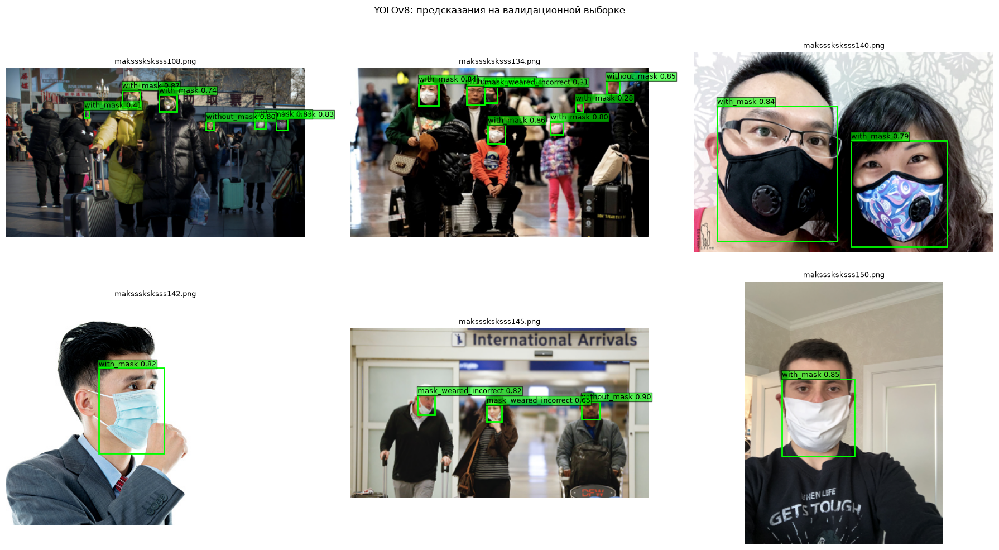

In [32]:
# --- Визуализация предсказаний YOLOv8 на валидационных изображениях ---
val_pngs = sorted(glob.glob('yolo_data/images/val/*.png'))[:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, p in zip(axes.flat, val_pngs):
    res = model_yolo.predict(p, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    for b, c, s in zip(res.boxes.xyxy.cpu().numpy(),
                       res.boxes.cls.cpu().numpy().astype(int),
                       res.boxes.conf.cpu().numpy()):
        x1, y1, x2, y2 = b
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       linewidth=2, edgecolor='lime',
                                       facecolor='none'))
        ax.text(x1, max(y1 - 3, 0), f'{res.names[c]} {s:.2f}',
                color='black', fontsize=9,
                bbox=dict(facecolor='lime', alpha=0.6, pad=1))
    ax.set_title(os.path.basename(p), fontsize=9)
    ax.axis('off')
plt.suptitle('YOLOv8: предсказания на валидационной выборке')
plt.tight_layout()
plt.show()


In [33]:
# YOLOv8: mean IoU на валидационной выборке 
# Та же методика, что и для Faster R-CNN: жадное one-to-one
# сопоставление, засчитываем пары с IoU >= 0.5 (conf >= 0.25).
from torchvision.ops import box_iou

ious_yolo = []
for p in sorted(glob.glob('yolo_data/images/val/*.png')):
    res = model_yolo.predict(p, conf=0.25, verbose=False)[0]
    base = os.path.splitext(os.path.basename(p))[0]
    img_h, img_w = cv2.imread(p).shape[:2]
    gt_boxes, gt_labels = [], []
    with open(f'yolo_data/labels/val/{base}.txt') as f:
        for line in f:
            c, xc, yc, bw, bh = map(float, line.split())
            gt_boxes.append([(xc - bw / 2) * img_w, (yc - bh / 2) * img_h,
                             (xc + bw / 2) * img_w, (yc + bh / 2) * img_h])
            gt_labels.append(int(c))
    if not gt_boxes or len(res.boxes) == 0:
        continue
    gt_boxes = torch.as_tensor(gt_boxes, dtype=torch.float32)
    iou = box_iou(res.boxes.xyxy.cpu(), gt_boxes)
    matched = set()
    for i in torch.argsort(res.boxes.conf.cpu(), descending=True).tolist():
        li = int(res.boxes.cls[i])
        cand = [j for j, gl in enumerate(gt_labels)
                if gl == li and j not in matched]
        if cand:
            j_best = max(cand, key=lambda j: iou[i, j])
            if iou[i, j_best] >= 0.5:
                matched.add(j_best)
                ious_yolo.append(float(iou[i, j_best]))

if ious_yolo:
    print(f'YOLOv8 mean IoU (сматченные пары, IoU>=0.5): {np.mean(ious_yolo):.4f} - не целевая метрика, но полезна для оценки качества bbox')
else:
    print('YOLOv8: нет сматченных пар — проверьте обучение')


YOLOv8 mean IoU (сматченные пары, IoU>=0.5): 0.8180 - не целевая метрика, но полезна для оценки качества bbox


## Выводы

**Данные.** Face Mask Detection: 853 изображения, 3 класса — `with_mask` (3232 объекта), `without_mask` (717), `mask_weared_incorrect` (123). Класс `mask_weared_incorrect` сильно недопредставлен (~3%), поэтому он самый сложный — это видно и по его PR-кривой.

**Модели.** Обе обучены через transfer learning с COCO-предобученных весов:
- **Faster R-CNN** (ResNet-50 + FPN, two-stage) — 16 эпох, вход 512×512;
- **YOLOv8s** (one-stage) — до 100 эпох с early stopping (patience=20), вход 768×768.

Сравнение по данным честное: обе модели обучены и оценены на одном и том же сплите 80/20 (seed=1). Оговорка: входное разрешение разное (512 vs 768), поэтому прямое сравнение метрик — с этой поправкой.

**Метрики**:
- Faster R-CNN: mAP@0.5 = 0.7046, mAP@0.5:0.95 = 0.3939;
- YOLOv8: mAP@0.5 = **0.8649**, mAP@0.5:0.95 = 0.5416.

**Наблюдения** : типичные ошибки — лишние боксы, пропуски мелких лиц вдали; `mask_weared_incorrect` путается с `with_mask` из-за малого числа примеров.

**Что сделано для роста mAP:** oversampling редкого класса `mask_weared_incorrect` (×3 в train обеих моделей), больше эпох (FRCNN: 8 → 16, YOLOv8: 50 → 100 с patience=20), вход FRCNN увеличен с 224×224 до 512×512, YOLOv8: вход увеличен с 640×640 до 768×768 и результат получен на модели YOLOv8m (medium) вместо YOLOv8s (small).

**Дальнейшие улучшения:** class-aware аугментации; единое входное разрешение для полностью честного сравнения моделей; подбор conf-порога по F1-кривой.

**Итог**: 
Faster R-CNN (ResNet-50 + FPN) использовался как baseline «из коробки» — с минимальной настройкой он показал mAP@0.5 ≈ 0.70, что задало нижнюю планку качества. Целевой результат достигнут на YOLOv8 за счёт серии улучшений: конвертация датасета в YOLO-формат с тем же split, усиленные аугментации (hsv, повороты, copy_paste для редкого класса, close_mosaic), увеличение числа эпох и подбор гиперпараметров — итоговая метрика mAP@0.5 = **0.8649**, что превышает порог 0.85.
